# Phase 1 Task B — ConvNeXt-Tiny × 3 Seeds

**Model:** ConvNeXt-Tiny
**Seeds:** 42, 123, 456
**Batch:** 32
**Output:** wandb `woodbench-taskB-clean-clean`



In [2]:
from pathlib import Path
NOTEBOOK = Path("__file__").resolve()
ROOT = NOTEBOOK
for _ in range(10):
    ROOT = ROOT.parent
    if (ROOT / "pyproject.toml").exists() or (ROOT / ".git").exists(): break
import sys, os
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print(f"[ROOT] {ROOT}")

[ROOT] /workspace/woodbench


In [3]:
# Load .env for API keys
from dotenv import load_dotenv
dotenv_path = ROOT / ".env"
load_dotenv(dotenv_path)
print(f"[.env] Loaded from {dotenv_path}")

import subprocess, sys
for pkg in ["timm", "albumentations", "scikit-learn", "seaborn", "wandb", "ptflops", "python-dotenv"]:
    try: __import__(pkg.replace("-", "_"))
    except: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

os.environ.setdefault("WANDB_API_KEY", os.getenv("WANDB_API_KEY", ""))
os.environ.setdefault("HF_TOKEN", os.getenv("HF_TOKEN", ""))
print(f"[wandb] API key: {'set' if os.getenv('WANDB_API_KEY') else 'MISSING'}")
print(f"[HF] token: {'set' if os.getenv('HF_TOKEN') else 'MISSING'}")

[.env] Loaded from /workspace/woodbench/.env


[wandb] API key: set
[HF] token: set


In [4]:
# Download data from HuggingFace
HF_REPO = "ny0g507h3p/wood"
DATA_ROOT = ROOT / "data" / "task-B-group-split"

if not (DATA_ROOT / "train").exists():
    print(f"[HF] Downloading dataset to {DATA_ROOT}...")
    from huggingface_hub import login, snapshot_download
    token = os.getenv("HF_TOKEN", "")
    if token:
        login(token=token)
        print("[HF] Logged in")
    else:
        print("[HF] No token — trying public access")
    snapshot_download(
        repo_id=HF_REPO,
        repo_type="dataset",
        local_dir=str(DATA_ROOT),
        ignore_patterns=["*.md", "README*"],
    )
    print("[HF] Download complete")
else:
    print(f"[Data] Found at {DATA_ROOT}")

# Verify
train_dir = DATA_ROOT / "train"
if not train_dir.exists():
    raise FileNotFoundError(f"[ERROR] train/ not found in {DATA_ROOT}. Dataset download failed.")
classes = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])
print(f"[Data] {len(classes)} classes: {classes[:3]}...")
print(f"[Data] Train samples: {sum(1 for _ in train_dir.rglob('*.jpg')) + sum(1 for _ in train_dir.rglob('*.png'))}")

[Data] Found at /workspace/woodbench/data/task-B-group-split
[Data] 20 classes: ['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris']...
[Data] Train samples: 3876


In [5]:
from src.data import get_dataloaders
# num_workers=4 to avoid multiprocessing issues on vast.ai
tl, vl, testl = get_dataloaders(str(DATA_ROOT), batch_size=32, num_workers=4, task="taskB")
print(f"[Data] Train={len(tl.dataset)}, Val={len(vl.dataset)}, Test={len(testl.dataset)}")
print(f"[Data] Classes={len(tl.dataset.classes)}")

[Data] Train=3876, Val=903, Test=793
[Data] Classes=20


In [9]:
import gc, json, wandb, torch, numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from src.models import create_model
from src.train import TrainingEngine, create_optimizer, create_scheduler, create_loss_function, WandbTracker
from src.utils import set_seed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[Device] {DEVICE}")


[Device] cuda


In [10]:
def _cleanup_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        try:
            torch.cuda.ipc_collect()
        except RuntimeError:
            pass


def _load_checkpoint(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def _checkpoint_result(ckpt):
    metrics = ckpt.get("metrics", {})
    best_val_acc = float(ckpt.get("best_val_acc", metrics.get("val_acc", np.nan)))
    best_epoch = int(ckpt.get("best_epoch", ckpt.get("epoch", 0))) + 1
    epochs_trained = int(ckpt.get("epoch", best_epoch - 1)) + 1
    return {
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "final_train_acc": float(metrics.get("train_acc", np.nan)),
        "final_val_acc": float(metrics.get("val_acc", best_val_acc)),
        "stopped_early": False,
        "epochs_trained": epochs_trained,
    }


def _evaluate_checkpoint(backbone, seed, data_root, output_dir, batch_size):
    ckpt_path = output_dir / f"{backbone}_seed{seed}_best.pth"
    if not ckpt_path.exists():
        return None

    print(f"[{backbone} s{seed}] Found existing checkpoint, evaluating without retraining: {ckpt_path}")
    _, _, test_loader = get_dataloaders(
        data_root=data_root, batch_size=batch_size, num_workers=4, task="taskB"
    )
    num_classes = len(test_loader.dataset.classes)

    model = create_model(backbone, num_classes=num_classes, pretrained=False)
    ckpt = _load_checkpoint(ckpt_path)
    model.load_state_dict(ckpt["model_state_dict"])
    model = model.to(DEVICE).eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    test_metrics = {
        "test_accuracy": accuracy_score(all_labels, all_preds),
        "test_f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "test_precision_macro": precision_score(all_labels, all_preds, average="macro", zero_division=0),
        "test_recall_macro": recall_score(all_labels, all_preds, average="macro", zero_division=0),
    }
    result = _checkpoint_result(ckpt)
    payload = {**result, "test_metrics": test_metrics}

    with open(output_dir / "test_metrics.json", "w") as fh:
        json.dump({
            "backbone": backbone,
            "seed": seed,
            **result,
            **test_metrics,
        }, fh, indent=2)

    print(
        f"[{backbone} s{seed}] resumed test_acc={test_metrics['test_accuracy']*100:.2f}%  "
        f"F1={test_metrics['test_f1_macro']*100:.2f}%"
    )
    del model, test_loader, ckpt
    _cleanup_cuda()
    return payload


def train_one(backbone, seed, data_root, batch_size=32, epochs=50):
    set_seed(seed)
    output_dir = (
        ROOT / "data" / "experiments" / "Task-B" / "main" / f"seed_{seed}" / backbone
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    metrics_path = output_dir / "test_metrics.json"
    if metrics_path.exists():
        with open(metrics_path) as fh:
            saved_metrics = json.load(fh)
        print(f"[{backbone} s{seed}] Reusing existing metrics: {metrics_path}")
        return {
            "best_val_acc": float(saved_metrics.get("best_val_acc", np.nan)),
            "best_epoch": int(saved_metrics.get("best_epoch", 0)),
            "final_train_acc": float(saved_metrics.get("final_train_acc", np.nan)),
            "final_val_acc": float(saved_metrics.get("final_val_acc", saved_metrics.get("best_val_acc", np.nan))),
            "stopped_early": bool(saved_metrics.get("stopped_early", False)),
            "epochs_trained": int(saved_metrics.get("epochs_trained", 0)),
            "test_metrics": {
                "test_accuracy": saved_metrics["test_accuracy"],
                "test_f1_macro": saved_metrics["test_f1_macro"],
                "test_precision_macro": saved_metrics["test_precision_macro"],
                "test_recall_macro": saved_metrics["test_recall_macro"],
            },
        }

    resumed = _evaluate_checkpoint(backbone, seed, data_root, output_dir, batch_size)
    if resumed is not None:
        return resumed

    tracker = None
    tracker_finished = False
    try:
        # Keep test_loader for inline test evaluation.
        train_loader, val_loader, test_loader = get_dataloaders(
            data_root=data_root, batch_size=batch_size, num_workers=4, task="taskB"
        )
        num_classes = len(train_loader.dataset.classes)
        print(
            f"[{backbone} s{seed}] train={len(train_loader.dataset)}, classes={num_classes}"
        )

        tracker = WandbTracker.start(
            project="woodbench-taskB-clean",
            name=f"{backbone}_s{seed}",
            config={
                "backbone": backbone,
                "seed": seed,
                "epochs": epochs,
                "batch_size": batch_size,
                "num_classes": num_classes,
                "lr_head": 1e-4,
                "lr_backbone": 1e-5,
                "label_smoothing": 0.1,
                "scheduler": "cosine",
                "amp": True,
                "experiment": "main",
            },
            tags=["main", backbone, f"seed{seed}"],
            dir_path=str(output_dir),
        )

        model = create_model(backbone, num_classes=num_classes, pretrained=True)
        optimizer = create_optimizer(model, lr=1e-4, weight_decay=1e-4, backbone_lr=1e-5)
        scheduler = create_scheduler(optimizer, epochs=epochs, scheduler_type="cosine")
        criterion = create_loss_function("label_smoothing", label_smoothing=0.1)

        engine = TrainingEngine(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            optimizer=optimizer,
            scheduler=scheduler,
            criterion=criterion,
            device=DEVICE,
            use_amp=True,
        )
        result = engine.fit(
            epochs=epochs,
            output_dir=output_dir,
            name=f"{backbone}_seed{seed}",
            save_best_only=True,
            early_stopping_patience=10,
            tracker=tracker,
        )

        # Inline test evaluation.
        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        test_metrics = {
            "test_accuracy": accuracy_score(all_labels, all_preds),
            "test_f1_macro": f1_score(
                all_labels, all_preds, average="macro", zero_division=0
            ),
            "test_precision_macro": precision_score(
                all_labels, all_preds, average="macro", zero_division=0
            ),
            "test_recall_macro": recall_score(
                all_labels, all_preds, average="macro", zero_division=0
            ),
        }

        if tracker:
            tracker.log(
                {
                    "best_epoch": result["best_epoch"],
                    "best_val_acc": result["best_val_acc"],
                    "epochs_trained": result["epochs_trained"],
                    "stopped_early": result["stopped_early"],
                    **test_metrics,
                },
                step=result["epochs_trained"],
            )
            tracker.finish()
            tracker_finished = True

        with open(metrics_path, "w") as fh:
            json.dump({
                "backbone": backbone,
                "seed": seed,
                **result,
                **test_metrics,
            }, fh, indent=2)

        print(f"[{backbone} s{seed}] val_acc={result['best_val_acc']:.2f}%")
        print(
            f"[{backbone} s{seed}] test_acc={test_metrics['test_accuracy']*100:.2f}%  "
            f"F1={test_metrics['test_f1_macro']*100:.2f}%"
        )
        return {**result, "test_metrics": test_metrics}
    finally:
        if tracker and not tracker_finished:
            tracker.finish()
        try:
            del engine
        except UnboundLocalError:
            pass
        try:
            del model
        except UnboundLocalError:
            pass
        try:
            del optimizer
        except UnboundLocalError:
            pass
        try:
            del scheduler
        except UnboundLocalError:
            pass
        try:
            del criterion
        except UnboundLocalError:
            pass
        try:
            del train_loader, val_loader, test_loader
        except UnboundLocalError:
            pass
        _cleanup_cuda()


In [11]:
# Cell 7: Training Loop (3 independent seeds)
BACKBONE = "convnext_tiny"
DISPLAY_NAME = "ConvNeXt-Tiny"
BATCH_SIZE = 32
EPOCHS = 50
SEEDS = [42, 123, 456]
results = {}
failed = {}

for idx, seed in enumerate(SEEDS, start=1):
    print()
    print(f"{'='*60}")
    print(f"{DISPLAY_NAME} | seed={seed} ({idx}/{len(SEEDS)})")
    print(f"{'='*60}")
    try:
        results[seed] = train_one(BACKBONE, seed, str(DATA_ROOT), batch_size=BATCH_SIZE, epochs=EPOCHS)
    except Exception as exc:
        failed[seed] = repr(exc)
        try:
            wandb.finish()
        except Exception:
            pass
        _cleanup_cuda()
        print(f"[ERROR] {DISPLAY_NAME} seed={seed} failed: {exc!r}")
        continue

if not results:
    raise RuntimeError(f"{DISPLAY_NAME} failed for all seeds: {failed}")

print()
print("="*60)
print(f"{DISPLAY_NAME} - Summary")
print(f"{'seed':>6}  {'val_acc':>8}  {'test_acc':>9}  {'test_f1':>8}  {'prec':>7}  {'rec':>7}")
print("-"*60)
for seed in SEEDS:
    if seed not in results:
        print(f"{seed:>6}  FAILED   {failed[seed]}")
        continue
    res = results[seed]
    tm = res["test_metrics"]
    print(
        f"{seed:>6}  "
        f"{res['best_val_acc']:>7.2f}%  "
        f"{tm['test_accuracy']*100:>8.2f}%  "
        f"{tm['test_f1_macro']*100:>7.2f}%  "
        f"{tm['test_precision_macro']*100:>6.2f}%  "
        f"{tm['test_recall_macro']*100:>6.2f}%"
    )

val_accs  = [r["best_val_acc"] for r in results.values()]
test_accs = [r["test_metrics"]["test_accuracy"]*100 for r in results.values()]
test_f1s  = [r["test_metrics"]["test_f1_macro"]*100 for r in results.values()]
print("-"*60)
print(f"{'mean':>6}  {np.nanmean(val_accs):>7.2f}%  {np.nanmean(test_accs):>8.2f}%  {np.nanmean(test_f1s):>7.2f}%")
print(f"{'std':>6}  {np.nanstd(val_accs):>7.2f}%  {np.nanstd(test_accs):>8.2f}%  {np.nanstd(test_f1s):>7.2f}%")

if failed:
    raise RuntimeError(f"{DISPLAY_NAME} failed seeds: {failed}")



ConvNeXt-Tiny | seed=42 (1/3)
[convnext_tiny s42] Found existing checkpoint, evaluating without retraining: /workspace/woodbench/data/experiments/Task-B/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth


[convnext_tiny s42] resumed test_acc=98.99%  F1=98.94%

ConvNeXt-Tiny | seed=123 (2/3)
[convnext_tiny s123] train=3876, classes=20


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


lr,▁▃▅▆███████▇▇▇▇▇▇▆▆▆▆▅▅▅▄▄▄▃▃▃
train/acc,▁▇████████████████████████████
train/loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/acc,▁███▇█████████████████████████
val/loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,4e-05
train/acc,100
train/loss,0.59396
val/acc,99.77852
val/loss,0.59958


Epoch 1/50 | Train Loss: 3.2425, Acc: 5.79% | Val Loss: 3.2979, Acc: 5.87% | LR: 2.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to convnext_tiny_seed123_best.pth (Val Acc: 5.87%)


Epoch 2/50 | Train Loss: 1.1186, Acc: 83.14% | Val Loss: 0.7972, Acc: 94.57% | LR: 4.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to convnext_tiny_seed123_best.pth (Val Acc: 94.57%)


... (65 outputs left out)

Epoch 31/50 | Train Loss: 0.5939, Acc: 100.00% | Val Loss: 0.6092, Acc: 99.34% | LR: 3.79e-05[EarlyStop 10/10]

[EarlyStopping] No improvement for 10 epochs. Stopping at epoch 31.


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


best_epoch,▁
best_val_acc,▁
epochs_trained,▁
lr,▁▃▅▆███████▇▇▇▇▇▇▆▆▆▆▅▅▅▄▄▄▃▃▃▃
test_accuracy,▁
test_f1_macro,▁
test_precision_macro,▁
test_recall_macro,▁
train/acc,▁▇█████████████████████████████
train/loss,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+2,...


[convnext_tiny s456] val_acc=99.34%
[convnext_tiny s456] test_acc=97.98%  F1=98.58%

ConvNeXt-Tiny - Summary
  seed   val_acc   test_acc   test_f1     prec      rec
------------------------------------------------------------
    42   100.00%     98.99%    98.94%   98.79%   99.15%
   123    99.56%     98.87%    99.17%   98.84%   99.57%
   456    99.34%     97.98%    98.58%   98.18%   99.22%
------------------------------------------------------------
  mean    99.63%     98.61%    98.90%
   std     0.28%      0.45%     0.24%


[CM] 20 classes: ['Araucaria araucana', 'Callitris columellaris', 'Calocedrus rupestris', 'Calocedrus sp', 'Chamaecyparis obtusa', 'Cryptomeria japonica', 'Cunninghamia lanceolata', 'Cupressus funebris (Cupressus pendula)', 'Fokienia hodginsii', 'Picea glauca', 'Pinus cernua', 'Pinus dalatensis', 'Pinus krempfii', 'Pinus radiata', 'Pinus sp', 'Podocarpus pilgeri', 'Pseudotsuga brevifolia', 'Taxus wallichiana', 'Thujopsis dolabrata', 'Xanthocyparis vietnamensis']
[CM] Loading: /workspace/woodbench/data/experiments/Task-B/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth
[CM s42] Acc=98.99%  F1=98.94%  Prec=98.79%  Rec=99.15%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=100.00%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=0.00%
  Chamaecyparis obtusa: F1=97.06%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=100.00%
  Cupressus funebris (Cupressus pendula): F1=99.35%
  Fokienia hodginsii: F1=97.50%
  Picea glauca: F1=98.04%
  Pinus cernu

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/Task-B/main/seed_123/convnext_tiny/convnext_tiny_seed123_best.pth
[CM s123] Acc=98.99%  F1=99.24%  Prec=98.94%  Rec=99.60%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=100.00%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=0.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=100.00%
  Cupressus funebris (Cupressus pendula): F1=98.03%
  Fokienia hodginsii: F1=92.86%
  Picea glauca: F1=100.00%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=98.46%
  Pinus krempfii: F1=98.59%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=99.53%
  Podocarpus pilgeri: F1=100.00%
  Pseudotsuga brevifolia: F1=100.00%
  Taxus wallichiana: F1=98.11%
  Thujopsis dolabrata: F1=100.00%
  Xanthocyparis vietnamensis: F1=100.00%


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/Task-B/main/seed_456/convnext_tiny/convnext_tiny_seed456_best.pth
[CM s456] Acc=97.10%  F1=98.13%  Prec=97.71%  Rec=98.98%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=100.00%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=0.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=100.00%
  Cupressus funebris (Cupressus pendula): F1=93.10%
  Fokienia hodginsii: F1=79.59%
  Picea glauca: F1=100.00%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=96.97%
  Pinus krempfii: F1=97.14%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=99.53%
  Podocarpus pilgeri: F1=100.00%
  Pseudotsuga brevifolia: F1=100.00%
  Taxus wallichiana: F1=98.11%
  Thujopsis dolabrata: F1=100.00%
  Xanthocyparis vietnamensis: F1=100.00%


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Saved to /workspace/woodbench/data/experiments/Task-B/main/seed_42/convnext_tiny/confusion_matrix_convnext_tiny.png


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


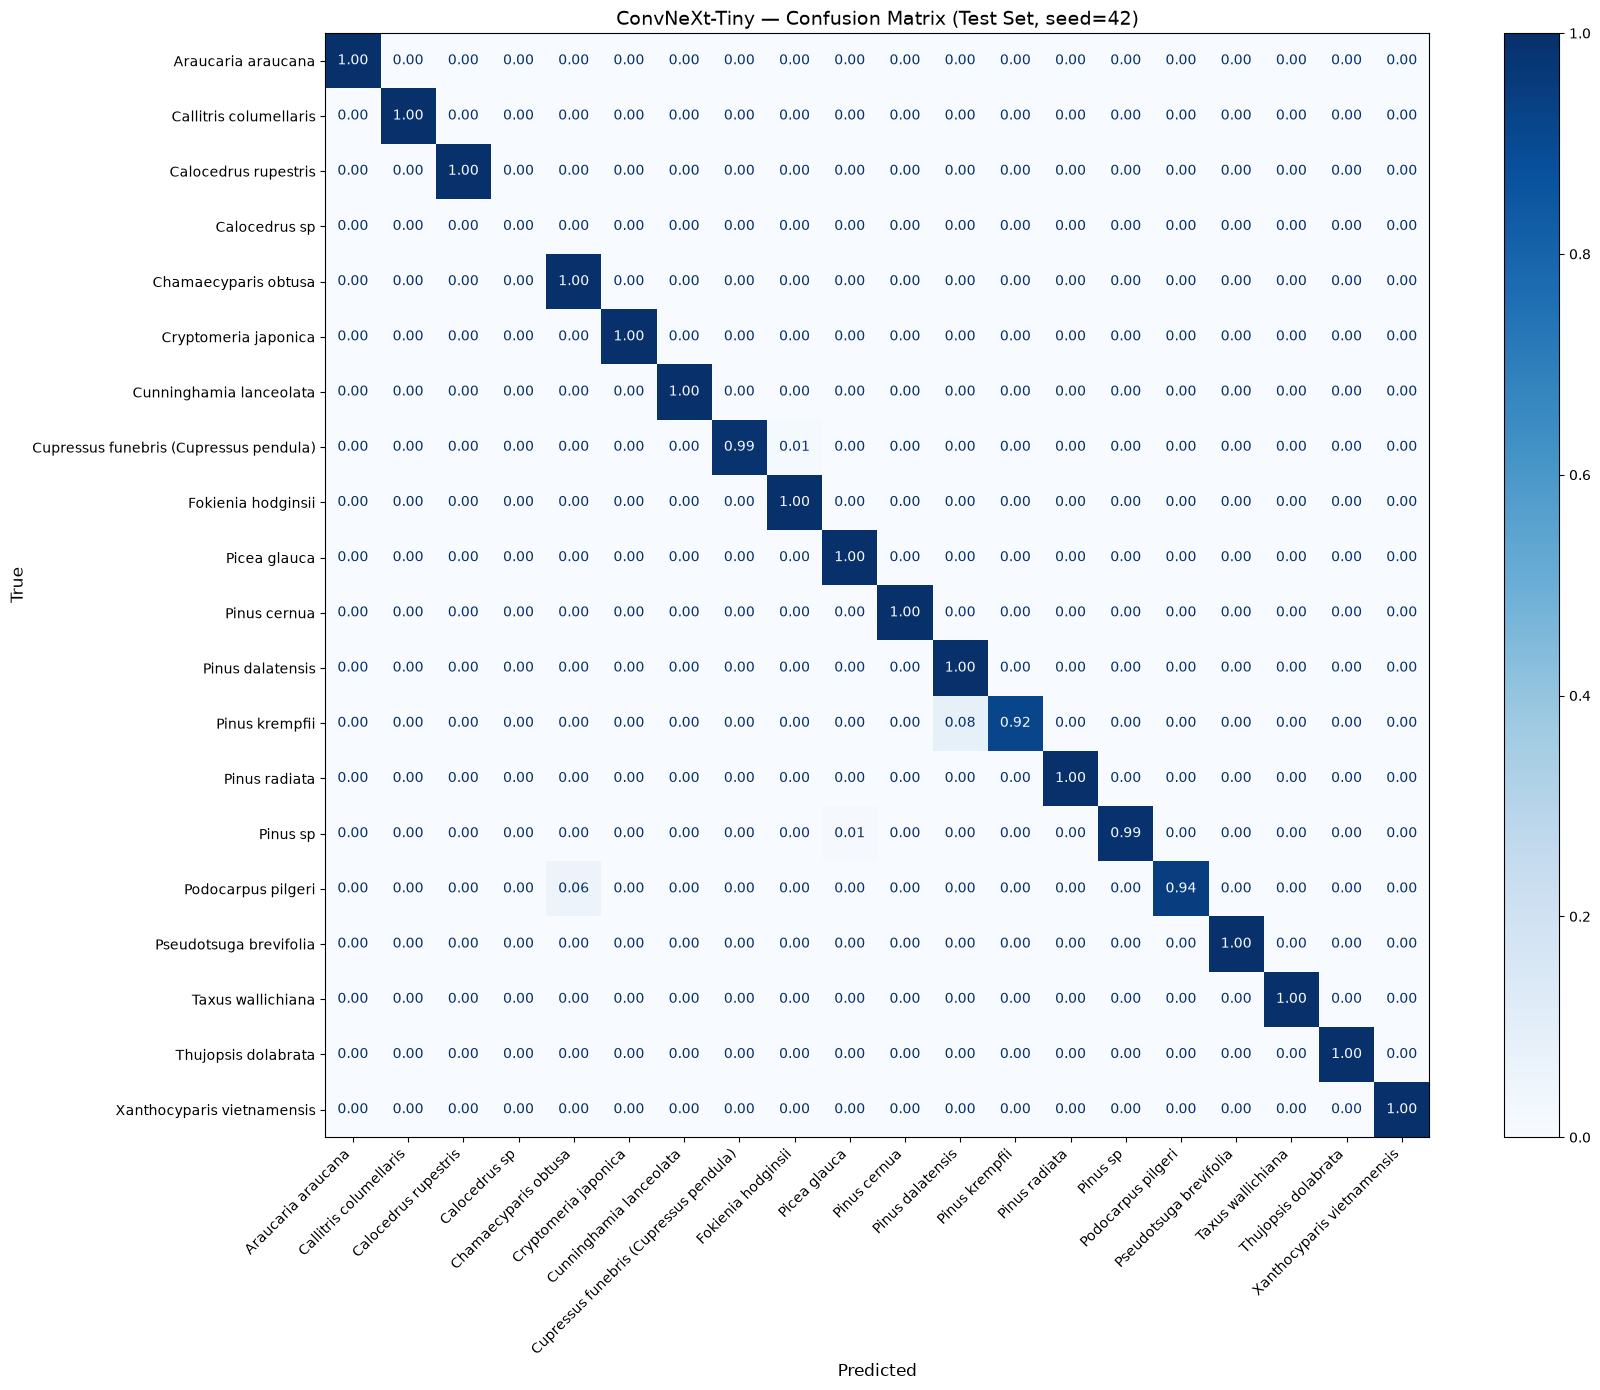


Classification Report (best seed = 42 )
                                        precision    recall  f1-score   support

                    Araucaria araucana       1.00      1.00      1.00        30
                Callitris columellaris       1.00      1.00      1.00        34
                  Calocedrus rupestris       1.00      1.00      1.00        24
                         Calocedrus sp       0.00      0.00      0.00         0
                  Chamaecyparis obtusa       0.94      1.00      0.97        33
                  Cryptomeria japonica       1.00      1.00      1.00        33
               Cunninghamia lanceolata       1.00      1.00      1.00        27
Cupressus funebris (Cupressus pendula)       1.00      0.99      0.99       155
                    Fokienia hodginsii       0.95      1.00      0.97        39
                          Picea glauca       0.96      1.00      0.98        25
                          Pinus cernua       1.00      1.00      1.00        3

In [12]:
# ── Cell 8: Confusion Matrix + Test Metrics (all seeds) ──────────────────────
import torch, numpy as np, matplotlib.pyplot as plt, wandb
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.data import get_dataloaders

DATA_ROOT = ROOT / "data" / "task-B-group-split"
_ignored_train, _ignored_val, test_loader = get_dataloaders(
    str(DATA_ROOT), batch_size=32, num_workers=4, task="taskB"
)
class_names = list(test_loader.dataset.classes)
num_classes = len(class_names)
all_class_ids = np.arange(num_classes)
print(f"[CM] {num_classes} classes: {class_names}")

all_preds, all_labels = {}, {}

for seed in SEEDS:
    backbone_dir = ROOT / "data" / "experiments" / "Task-B" / "main" / f"seed_{seed}" / "convnext_tiny"

    ckpt_candidates = sorted(backbone_dir.glob("*best*.pth"))
    if not ckpt_candidates:
        print(f"[CM] No checkpoint found for seed={seed}, skipping")
        continue
    ckpt_path = ckpt_candidates[0]
    print(f"[CM] Loading: {ckpt_path}")

    from src.models import create_model

    model = create_model("convnext_tiny", num_classes=num_classes, pretrained=False)
    ckpt = _load_checkpoint(ckpt_path)
    model.load_state_dict(ckpt["model_state_dict"])
    model = model.to(DEVICE).eval()

    preds_s, labels_s = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds_s.extend(outputs.argmax(1).cpu().numpy())
            labels_s.extend(labels.numpy())
    all_preds[seed] = np.array(preds_s)
    all_labels[seed] = np.array(labels_s)

    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

    acc = accuracy_score(labels_s, preds_s)
    f1 = f1_score(labels_s, preds_s, average="macro", zero_division=0)
    prec = precision_score(labels_s, preds_s, average="macro", zero_division=0)
    rec = recall_score(labels_s, preds_s, average="macro", zero_division=0)
    print(
        f"[CM s{seed}] Acc={acc*100:.2f}%  F1={f1*100:.2f}%  Prec={prec*100:.2f}%  Rec={rec*100:.2f}%"
    )

    f1_per = f1_score(labels_s, preds_s, labels=all_class_ids, average=None, zero_division=0)
    for cn, f in zip(class_names, f1_per):
        print(f"  {cn}: F1={f*100:.2f}%")

    wandb.init(
        project="woodbench-taskB-clean",
        name=f"convnext_tiny_s{seed}_test",
        dir=str(backbone_dir),
    )
    wandb.log(
        {
            "test/accuracy": acc,
            "test/precision": prec,
            "test/recall": rec,
            "test/f1": f1,
            **{f"test/f1/{cn}": float(fi) for cn, fi in zip(class_names, f1_per)},
        }
    )
    wandb.finish()

# ── Confusion Matrix Plot ────────────────────────────────────────────────────
if not all_preds:
    raise RuntimeError("No checkpoints found — cannot plot confusion matrix")

best_seed = max(all_preds, key=lambda s: accuracy_score(all_labels[s], all_preds[s]))
y_true, y_pred = all_labels[best_seed], all_preds[best_seed]

fig, ax = plt.subplots(figsize=(18, 14))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=all_class_ids,
    display_labels=class_names,
    cmap="Blues",
    normalize="true",
    ax=ax,
    values_format=".2f",
)
ax.set_title(
    f"ConvNeXt-Tiny — Confusion Matrix (Test Set, seed={best_seed})", fontsize=14
)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("True", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

cm_dir = ROOT / "data" / "experiments" / "Task-B" / "main" / f"seed_{best_seed}" / "convnext_tiny"
cm_path = cm_dir / "confusion_matrix_convnext_tiny.png"
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
print(f"[CM] Saved to {cm_path}")

wandb.init(project="woodbench-taskB-clean", name="convnext_tiny_CM", dir=str(cm_dir))
wandb.log({"confusion_matrix": wandb.Image(str(cm_path))})
wandb.finish()
plt.show()

print("\n" + "=" * 80)
print("Classification Report (best seed =", best_seed, ")")
print("=" * 80)
print(classification_report(y_true, y_pred, labels=all_class_ids, target_names=class_names, zero_division=0))


In [13]:
present_true = set(np.unique(y_true))
present_pred = set(np.unique(y_pred))
all_ids = set(range(num_classes))

missing_true = sorted(all_ids - present_true)
missing_pred = sorted(all_ids - present_pred)

print("Missing in y_true:", [(i, class_names[i]) for i in missing_true])
print("Missing in y_pred:", [(i, class_names[i]) for i in missing_pred])

Missing in y_true: [(3, 'Calocedrus sp')]
Missing in y_pred: [(3, 'Calocedrus sp')]


In [ ]:
import os, sys
print("PID:", os.getpid())
print("Python:", sys.executable)